# 04 – Fine-tune Cellpose-SAM on Fluo-N2DL-HeLa (Kaggle, GPU)

**Purpose:** Fine-tune the pretrained Cellpose-SAM model on this dataset and test whether it segments
better than the pretrained model.

**Runs on:** Kaggle Notebook with GPU (not locally). Input: the Fluo-N2DL-HeLa dataset attached via *Add Input*.

### Design
- **Train on sequence 02**, silver-truth labels (complete coverage, all 92 frames).
  Every 10th frame is held out to monitor the test loss during training.
- **Evaluate on sequence 01**, gold truth – never seen during training. Same metrics as notebook 03.
- Gold truth is not used for training: it is only partially annotated, so unannotated nuclei would be learned as background.
- Limitation: the model learns the outline style of the silver truth, not of the manual annotation.

**Training parameters:** defaults of the official Cellpose-SAM training notebook
(100 epochs, learning rate 1e-5, weight decay 0.1, batch size 1).

## 1. Check GPU and install Cellpose
The Cellpose version is pinned to the one used locally (4.2.1.1) so that results are comparable.
Requires *Settings → Accelerator → GPU* and *Settings → Internet → on* (for pip).

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q cellpose==4.2.1.1 tifffile

name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB


## 2. Imports and settings
The dataset folder is searched under `/kaggle/input`, because its exact mount path depends on how it was added.

In [2]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from skimage.segmentation import relabel_sequential
from cellpose import models, core, train, io

io.logger_setup()   # prints training progress

INPUT = Path("/kaggle/input")
WORK = Path("/kaggle/working")   # everything saved here appears in the notebook output

DATA = next(p for p in INPUT.rglob("Fluo-N2DL-HeLa") if (p / "01").is_dir())
SEQ_TRAIN, SEQ_EVAL = "02", "01"
TEST_EVERY = 10
FULL_FRAMES = [13, 52]
IOU_THRESHOLD = 0.5

N_EPOCHS, LEARNING_RATE, WEIGHT_DECAY, BATCH_SIZE = 100, 1e-5, 0.1, 1
MODEL_NAME = "cpsam_hela_seq02"

print("data:", DATA)
print("GPU available:", core.use_gpu())

creating new log file
[GUI INFO] : WRITING LOG OUTPUT TO /root/.cellpose/run.log

cellpose version: 	4.2.1.1 
platform:       	linux 
python version: 	3.13.15 
torch version:  	2.11.0+cu128
2026-10-30 11:45:23,729 [io INFO] WRITING LOG OUTPUT TO /root/.cellpose/run.log
2026-10-30 11:45:23,729 [io INFO] 
cellpose version: 	4.2.1.1 
platform:       	linux 
python version: 	3.13.15 
torch version:  	2.11.0+cu128
data: /kaggle/input/datasets/xunbch/hela-train/Fluo-N2DL-HeLa
2026-10-30 11:45:24,682 [core INFO] ** TORCH CUDA version installed and working. **
GPU available: True


## 3. Load training data (sequence 02, silver truth)
Image `tTTT.tif` belongs to mask `man_segTTT.tif`. Images are passed as 2D arrays;
Cellpose converts them to its 3-channel input and normalises them internally.

In [3]:
train_x, train_y, test_x, test_y = [], [], [], []
for img_path in sorted((DATA / SEQ_TRAIN).glob("t*.tif")):
    t = int(img_path.stem[1:])
    mask_path = DATA / f"{SEQ_TRAIN}_ST" / "SEG" / f"man_seg{t:03d}.tif"
    if not mask_path.exists():
        continue
    img, mask = tifffile.imread(img_path), tifffile.imread(mask_path)
    if t % TEST_EVERY == 0:
        test_x.append(img); test_y.append(mask)
    else:
        train_x.append(img); train_y.append(mask)

print(f"train: {len(train_x)} | test: {len(test_x)} | image shape {train_x[0].shape}, {train_x[0].dtype}")

train: 82 | test: 10 | image shape (700, 1100), uint16


## 4. Fine-tune
Starts from the pretrained Cellpose-SAM weights. Progress (loss per epoch) is printed by Cellpose.
The model is saved to `/kaggle/working/models/`.

In [4]:
model = models.CellposeModel(gpu=True)

t0 = time.time()
model_path, train_losses, test_losses = train.train_seg(
    model.net,
    train_data=train_x, train_labels=train_y,
    test_data=test_x, test_labels=test_y,
    batch_size=BATCH_SIZE, n_epochs=N_EPOCHS,
    learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
    nimg_per_epoch=len(train_x),
    save_path=WORK, model_name=MODEL_NAME,
)
train_minutes = (time.time() - t0) / 60
print(f"training time: {train_minutes:.0f} min | model: {model_path}")

2026-10-30 11:46:17,743 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-30 11:46:17,744 [core INFO] >>>> using GPU (CUDA)
2026-10-30 11:46:17,745 [models INFO] Downloading: "https://huggingface.co/mouseland/cellpose-sam/resolve/main/cpsam_v2" to /root/.cellpose/models/cpsam_v2



100%|██████████| 1.15G/1.15G [00:08<00:00, 151MB/s]


2026-10-30 11:46:28,938 [models INFO] >>>> loading model /root/.cellpose/models/cpsam_v2
2026-10-30 11:46:29,533 [train INFO] >>> converting bfloat16 network to float32 for training
2026-10-30 11:46:29,542 [dynamics INFO] computing flows for labels


100%|██████████| 82/82 [00:09<00:00,  9.08it/s]

2026-10-30 11:46:38,696 [dynamics INFO] computing flows for labels



100%|██████████| 10/10 [00:01<00:00,  9.76it/s]

2026-10-30 11:46:39,737 [train INFO] >>> computing diameters



100%|██████████| 10/10 [00:00<00:00, 333.58it/s]

2026-10-30 11:46:40,013 [train INFO] >>> normalizing {'lowhigh': None, 'percentile': None, 'normalize': True, 'norm3D': True, 'sharpen_radius': 0, 'smooth_radius': 0, 'tile_norm_blocksize': 0, 'tile_norm_smooth3D': 1, 'invert': False}


2026-10-30 11:46:41,877 [train INFO] >>> n_epochs=100, n_train=82, n_test=10, bsize=256, batch_size=1, nimg_per_epoch=82
2026-10-30 11:46:41,878 [train INFO] >>> AdamW, learning_rate=0.00001, weight_decay=0.10000
2026-10-30 11:46:41,881 [train INFO] >>> saving model to /kaggle/working/models/cpsam_hela_seq02
2026-10-30 11:48:00,545 [train INFO] 0, train_loss=0.1730, test_loss=0.1591, LR=0.000000, time 78.66s
2026-10-30 11:54:23,422 [train INFO] 5, train_loss=0.1376, test_loss=0.1104, LR=0.000006, time 461.54s
2026-10-30 12:00:46,275 [train INFO] 10, train_loss=0.1054, test_loss=0.1204, LR=0.000010, time 844.39s
2026-10-30 12:13:26,925 [train INFO] 20, train_loss=0.0991, test_loss=0.1050, LR=0.000010, time 1605.04s
2026-10-30 12:26:06,965 [train INFO] 30, train_loss=0.0946, test_loss=0.1042, LR=0.000010, time 2365.08s
2026-10-30 12:38:47,293 [train INFO] 40, train_loss=0.0932, test_loss=0.1022, LR=0.000010, time 3125.41s
2026-10-30 12:51:29,251 [train INFO] 50, train_loss=0.0863, test_l

## 5. Learning curves
Training loss should fall; the test loss (held-out frames of sequence 02) shows whether the model
generalises or starts to overfit (test loss rising again). Test loss is only computed at some epochs.

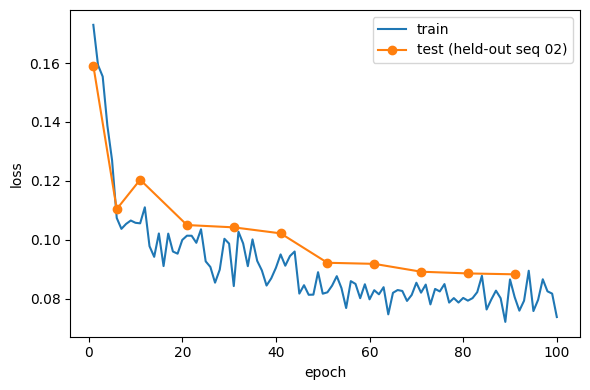

In [5]:
epochs = np.arange(1, len(train_losses) + 1)
has_test = np.asarray(test_losses) > 0

plt.figure(figsize=(6, 4))
plt.plot(epochs, train_losses, label="train")
plt.plot(epochs[has_test], np.asarray(test_losses)[has_test], "o-", label="test (held-out seq 02)")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend()
plt.tight_layout()
plt.savefig(WORK / "learning_curves.png", dpi=150)
plt.show()

pd.DataFrame({"epoch": epochs, "train_loss": train_losses, "test_loss": test_losses}) \
  .to_csv(WORK / "learning_curves.csv", index=False)

## 6. Evaluation functions
Identical to notebook 03 (IoU > 0.5 matching; detection metrics on fully annotated frames;
SEG-like score per reference nucleus on all gold-truth frames).

In [6]:
def iou_matrix(gt_lab, pred_lab):
    n_gt, n_pred = int(gt_lab.max()), int(pred_lab.max())
    codes = gt_lab.ravel().astype(np.int64) * (n_pred + 1) + pred_lab.ravel().astype(np.int64)
    overlap = np.bincount(codes, minlength=(n_gt + 1) * (n_pred + 1)).reshape(n_gt + 1, n_pred + 1)
    union = overlap.sum(axis=1, keepdims=True) + overlap.sum(axis=0, keepdims=True) - overlap
    return (overlap / np.maximum(union, 1))[1:, 1:]


def evaluate(gt_lab, pred_lab, thresh=IOU_THRESHOLD):
    gt_lab = relabel_sequential(gt_lab)[0]
    pred_lab = relabel_sequential(pred_lab)[0]
    iou = iou_matrix(gt_lab, pred_lab)
    n_gt, n_pred = iou.shape
    hits = iou > thresh
    tp = int(hits.sum())
    best = iou.max(axis=1) if n_pred else np.zeros(n_gt)
    return {
        "n_gt": n_gt, "n_pred": n_pred, "tp": tp, "fp": n_pred - tp, "fn": n_gt - tp,
        "precision": tp / n_pred if n_pred else np.nan,
        "recall": tp / n_gt if n_gt else np.nan,
        "f1": 2 * tp / (n_gt + n_pred) if (n_gt + n_pred) else np.nan,
        "mean_iou_matched": iou[hits].mean() if tp else np.nan,
        "seg_like": np.where(best > thresh, best, 0).mean() if n_gt else np.nan,
    }

## 7. Evaluate pretrained vs. fine-tuned on sequence 01
Both models segment the same 28 gold-truth frames of the unseen sequence.

In [7]:
gt_files = sorted((DATA / f"{SEQ_EVAL}_GT" / "SEG").glob("man_seg*.tif"))
frames = [int("".join(c for c in f.stem if c.isdigit())) for f in gt_files]
gt = {t: tifffile.imread(f) for t, f in zip(frames, gt_files)}
raw = {t: tifffile.imread(DATA / SEQ_EVAL / f"t{t:03d}.tif") for t in frames}

candidates = {
    "pretrained": models.CellposeModel(gpu=True),
    "fine-tuned": models.CellposeModel(gpu=True, pretrained_model=str(model_path)),
}
pred = {}
for name, m in candidates.items():
    t0 = time.time()
    pred[name] = {t: m.eval(raw[t])[0] for t in frames}
    print(f"{name}: {len(frames)} frames in {time.time() - t0:.0f} s")

2026-10-30 13:53:56,657 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-30 13:53:56,658 [core INFO] >>>> using GPU (CUDA)
2026-10-30 13:53:58,489 [models INFO] >>>> loading model /root/.cellpose/models/cpsam_v2
2026-10-30 13:53:59,033 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-30 13:53:59,035 [core INFO] >>>> using GPU (CUDA)
2026-10-30 13:54:00,855 [models INFO] >>>> loading model /kaggle/working/models/cpsam_hela_seq02


/usr/local/lib/python3.13/dist-packages/cellpose/dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


pretrained: 28 frames in 259 s
fine-tuned: 28 frames in 256 s


In [8]:
rows = [{"frame": t, "method": name, "full_frame": t in FULL_FRAMES, **evaluate(gt[t], pred[name][t])}
        for name in pred for t in frames]
res = pd.DataFrame(rows)
res.to_csv(WORK / "metrics_pretrained_vs_finetuned_seq01.csv", index=False)

cols = ["frame", "method", "n_gt", "n_pred", "tp", "fp", "fn", "precision", "recall", "f1", "mean_iou_matched"]
print("Fully annotated frames:")
print(res[res["full_frame"]][cols].round(3).to_string(index=False))

weighted = res.groupby("method").apply(
    lambda d: np.average(d["seg_like"], weights=d["n_gt"]), include_groups=False)
print("\nSEG-like score, all GT frames, weighted by annotated nuclei:")
print(weighted.round(3).to_string())

partial = res[~res["full_frame"]].pivot(index="frame", columns="method", values="seg_like")
print("\nSEG-like score on partial frames (selected, often difficult nuclei):")
print(partial.round(3).to_string())

Fully annotated frames:
 frame     method  n_gt  n_pred  tp  fp  fn  precision  recall    f1  mean_iou_matched
    13 pretrained    59      58  54   4   5      0.931   0.915 0.923             0.843
    52 pretrained   110     116 108   8   2      0.931   0.982 0.956             0.869
    13 fine-tuned    59      55  55   0   4      1.000   0.932 0.965             0.910
    52 fine-tuned   110     107 107   0   3      1.000   0.973 0.986             0.907

SEG-like score, all GT frames, weighted by annotated nuclei:
method
fine-tuned    0.811
pretrained    0.779

SEG-like score on partial frames (selected, often difficult nuclei):
method  fine-tuned  pretrained
frame                         
12           0.804       0.722
14           0.408       0.595
15           0.876       0.774
20           0.814       0.759
21           0.544       0.827
22           0.467       0.624
23           0.626       0.797
25           0.882       0.815
29           0.874       0.799
38           0.716   

## Results (2026-10-30, version "v1 – seq02 ST, 100 epochs, lr 1e-5")

- **Training time / GPU:** ~76 s per epoch on one Tesla T4 (Kaggle, 2 × T4 available, Cellpose uses one);
  100 epochs ≈ 127, min; whole notebook incl. installation and evaluation ≈ 2 h 18 min.
- **Base model:** Cellpose-SAM weights `cpsam_v2` (default in cellpose 4.2.1.1).
- **Learning curves:** both losses fall steadily without signs of overfitting
  (train 0.173 → 0.074, held-out test 0.159 → 0.088). Plateau between epochs 20–40, further drop once the
  learning rate is halved (from epoch 50). After ~epoch 60 the learning rate is so small that little changes –
  a shorter schedule (~60 epochs) would likely give a similar model in less time.
- **Reproducibility:** the pretrained model gives identical results on Kaggle (T4) and locally (M2, notebook 03).
- **Fully annotated frames (13, 52), pretrained → fine-tuned:**
  F1 0.92 → 0.97 (frame 13) and 0.96 → 0.99 (frame 52); precision 0.93 → 1.00 (no false positives –
  border-cut nuclei are no longer segmented, consistent with the silver-truth convention);
  IoU of matched nuclei 0.84–0.87 → 0.91 (silver truth: 0.92).
- **SEG-like score (all 28 GT frames, weighted by annotated nuclei):** 0.78 → 0.81 (silver truth: 0.88).
- **Partial frames (selected, often difficult nuclei):** mixed – 16 frames better, 11 worse.
  Large gains on the mitotic frames 51 (0.29 → 0.77) and 53 (0.39 → 0.73);
  losses in frames 14–23 where some annotated nuclei are no longer found (recall down to 0.50–0.75).
  Interpretation: the fine-tuned model is more conservative and draws outlines in the silver-truth style;
  it may also have learned omissions of the silver truth (hypothesis, to be checked in notebook 05).
  Frame-level values on partial frames rest on few nuclei → paired per-nucleus analysis in R.